In [ ]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("Spotify Big Data Analytics") \
    .getOrCreate()

In [ ]:
df = spark.read \
    .option("header", True) \
    .option("quote", '"') \
    .option("escape", '"') \
    .option("multiLine", False) \
    .csv("/content/dataset.csv")

In [ ]:
print("Jumlah Baris :", df.count())
print("Jumlah Kolom :", len(df.columns))

Jumlah Baris : 114000
Jumlah Kolom : 21


In [ ]:
df.show(5, truncate=False)

+---+----------------------+----------------------+------------------------------------------------------+--------------------------+----------+-----------+--------+------------+------+---+--------+----+-----------+------------+----------------+--------+-------+-------+--------------+-----------+
|_c0|track_id              |artists               |album_name                                            |track_name                |popularity|duration_ms|explicit|danceability|energy|key|loudness|mode|speechiness|acousticness|instrumentalness|liveness|valence|tempo  |time_signature|track_genre|
+---+----------------------+----------------------+------------------------------------------------------+--------------------------+----------+-----------+--------+------------+------+---+--------+----+-----------+------------+----------------+--------+-------+-------+--------------+-----------+
|0  |5SuOikwiRyPMVoIQDJUgSV|Gen Hoshino           |Comedy                                                |

In [ ]:
df.printSchema()

root
 |-- _c0: string (nullable = true)
 |-- track_id: string (nullable = true)
 |-- artists: string (nullable = true)
 |-- album_name: string (nullable = true)
 |-- track_name: string (nullable = true)
 |-- popularity: string (nullable = true)
 |-- duration_ms: string (nullable = true)
 |-- explicit: string (nullable = true)
 |-- danceability: string (nullable = true)
 |-- energy: string (nullable = true)
 |-- key: string (nullable = true)
 |-- loudness: string (nullable = true)
 |-- mode: string (nullable = true)
 |-- speechiness: string (nullable = true)
 |-- acousticness: string (nullable = true)
 |-- instrumentalness: string (nullable = true)
 |-- liveness: string (nullable = true)
 |-- valence: string (nullable = true)
 |-- tempo: string (nullable = true)
 |-- time_signature: string (nullable = true)
 |-- track_genre: string (nullable = true)



In [ ]:
df.describe().show()

+-------+-----------------+--------------------+-----------------+----------------------------+--------------+-----------------+------------------+--------+-------------------+-------------------+------------------+-----------------+-------------------+-------------------+-------------------+------------------+-------------------+------------------+------------------+------------------+-----------+
|summary|              _c0|            track_id|          artists|                  album_name|    track_name|       popularity|       duration_ms|explicit|       danceability|             energy|               key|         loudness|               mode|        speechiness|       acousticness|  instrumentalness|           liveness|           valence|             tempo|    time_signature|track_genre|
+-------+-----------------+--------------------+-----------------+----------------------------+--------------+-----------------+------------------+--------+-------------------+-------------------+

In [ ]:
print(df.count())

114000


In [ ]:
df = df.withColumnRenamed("_c0", "id")

In [ ]:
from pyspark.sql.functions import col, count, when

missing = df.select([
    count(when(col(c).isNull() | (col(c) == ""), c)).alias(c)
    for c in df.columns
])

missing.show(truncate=False)

+---+--------+-------+----------+----------+----------+-----------+--------+------------+------+---+--------+----+-----------+------------+----------------+--------+-------+-----+--------------+-----------+
|id |track_id|artists|album_name|track_name|popularity|duration_ms|explicit|danceability|energy|key|loudness|mode|speechiness|acousticness|instrumentalness|liveness|valence|tempo|time_signature|track_genre|
+---+--------+-------+----------+----------+----------+-----------+--------+------------+------+---+--------+----+-----------+------------+----------------+--------+-------+-----+--------------+-----------+
|0  |0       |1      |1         |1         |0         |0          |0       |0           |0     |0  |0       |0   |0          |0           |0               |0       |0      |0    |0             |0          |
+---+--------+-------+----------+----------+----------+-----------+--------+------------+------+---+--------+----+-----------+------------+----------------+--------+-------

In [ ]:
print("Sebelum:", df.count())

df = df.dropDuplicates()

print("Sesudah:", df.count())

Sebelum: 114000
Sesudah: 114000


In [ ]:
from pyspark.sql.functions import expr

numeric_columns = {
    "popularity": "int",
    "duration_ms": "int",
    "danceability": "double",
    "energy": "double",
    "key": "int",
    "loudness": "double",
    "mode": "int",
    "speechiness": "double",
    "acousticness": "double",
    "instrumentalness": "double",
    "liveness": "double",
    "valence": "double",
    "tempo": "double",
    "time_signature": "int"
}

for column, dtype in numeric_columns.items():
    df = df.withColumn(
        column,
        expr(f"try_cast(`{column}` AS {dtype})")
    )

In [ ]:
df = df.dropna(subset=list(numeric_columns.keys()))

In [ ]:
df.printSchema()

root
 |-- id: string (nullable = true)
 |-- track_id: string (nullable = true)
 |-- artists: string (nullable = true)
 |-- album_name: string (nullable = true)
 |-- track_name: string (nullable = true)
 |-- popularity: integer (nullable = true)
 |-- duration_ms: integer (nullable = true)
 |-- explicit: string (nullable = true)
 |-- danceability: double (nullable = true)
 |-- energy: double (nullable = true)
 |-- key: integer (nullable = true)
 |-- loudness: double (nullable = true)
 |-- mode: integer (nullable = true)
 |-- speechiness: double (nullable = true)
 |-- acousticness: double (nullable = true)
 |-- instrumentalness: double (nullable = true)
 |-- liveness: double (nullable = true)
 |-- valence: double (nullable = true)
 |-- tempo: double (nullable = true)
 |-- time_signature: integer (nullable = true)
 |-- track_genre: string (nullable = true)



In [ ]:
df.show(5, truncate=False)

+---+----------------------+-------------+--------------------------------+----------------------------+----------+-----------+--------+------------+------+---+--------+----+-----------+------------+----------------+--------+-------+-------+--------------+-----------+
|id |track_id              |artists      |album_name                      |track_name                  |popularity|duration_ms|explicit|danceability|energy|key|loudness|mode|speechiness|acousticness|instrumentalness|liveness|valence|tempo  |time_signature|track_genre|
+---+----------------------+-------------+--------------------------------+----------------------------+----------+-----------+--------+------------+------+---+--------+----+-----------+------------+----------------+--------+-------+-------+--------------+-----------+
|52 |2DHDuADAHoUW6n0z80RLQF|Andrew Belle |Black Bear                      |Pieces                      |60        |241119     |False   |0.494       |0.652 |6  |-5.863  |0   |0.0314     |0.0754 

In [ ]:
from pyspark.sql.functions import avg, desc

genre_popularity = (
    df.groupBy("track_genre")
      .agg(
          avg("popularity").alias("Average_Popularity")
      )
      .orderBy(desc("Average_Popularity"))
)

genre_popularity.show(10, truncate=False)

+-----------+------------------+
|track_genre|Average_Popularity|
+-----------+------------------+
|pop-film   |59.283            |
|k-pop      |56.896            |
|chill      |53.651            |
|sad        |52.379            |
|grunge     |49.594            |
|indian     |49.539            |
|anime      |48.772            |
|emo        |48.128            |
|sertanejo  |47.866            |
|pop        |47.576            |
+-----------+------------------+
only showing top 10 rows


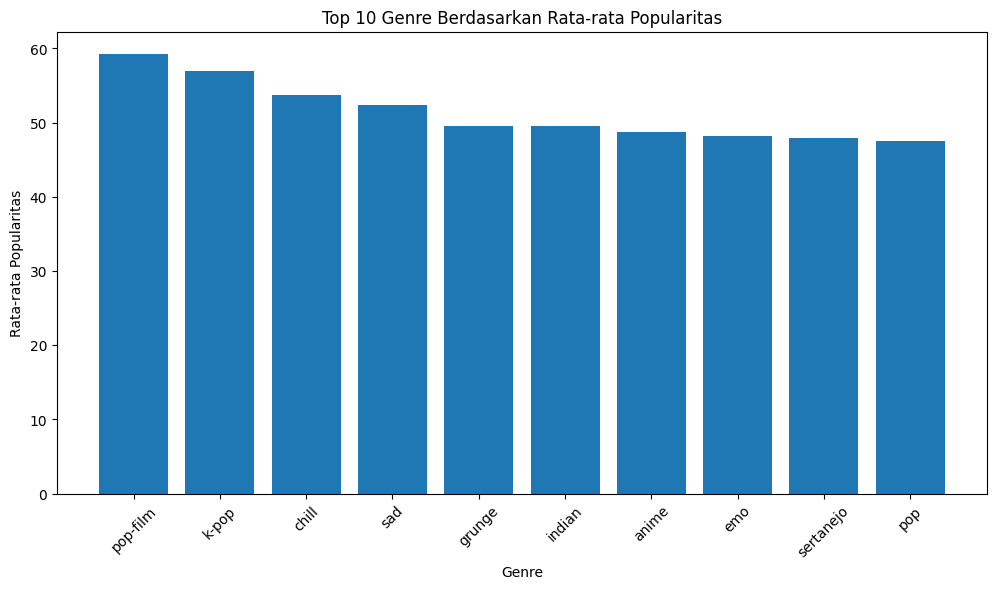

In [ ]:
import matplotlib.pyplot as plt

genre_pop_pd = genre_popularity.limit(10).toPandas()

plt.figure(figsize=(12,6))

plt.bar(
    genre_pop_pd["track_genre"],
    genre_pop_pd["Average_Popularity"]
)

plt.xticks(rotation=45)

plt.xlabel("Genre")
plt.ylabel("Rata-rata Popularitas")

plt.title("Top 10 Genre Berdasarkan Rata-rata Popularitas")

plt.show()

In [ ]:
explicit_count = (
    df.groupBy("explicit")
      .agg(
          count("*").alias("Jumlah")
      )
)

explicit_count.show()

+--------+------+
|explicit|Jumlah|
+--------+------+
|   False|104253|
|    True|  9747|
+--------+------+



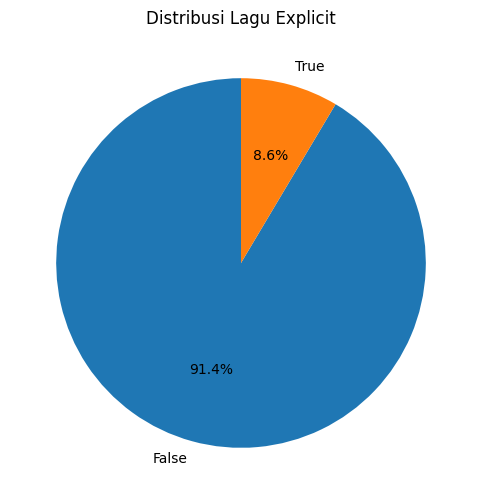

In [ ]:
explicit_pd = explicit_count.toPandas()

plt.figure(figsize=(6,6))

plt.pie(
    explicit_pd["Jumlah"],
    labels=explicit_pd["explicit"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribusi Lagu Explicit")
plt.show()

In [ ]:
artist_count = (
    df.groupBy("artists")
      .agg(
          count("*").alias("Jumlah_Lagu")
      )
      .orderBy(desc("Jumlah_Lagu"))
)

artist_count.show(10, truncate=False)

+---------------+-----------+
|artists        |Jumlah_Lagu|
+---------------+-----------+
|The Beatles    |279        |
|George Jones   |271        |
|Stevie Wonder  |236        |
|Linkin Park    |224        |
|Ella Fitzgerald|222        |
|Prateek Kuhad  |217        |
|Feid           |202        |
|Chuck Berry    |190        |
|Håkan Hellström|183        |
|OneRepublic    |181        |
+---------------+-----------+
only showing top 10 rows


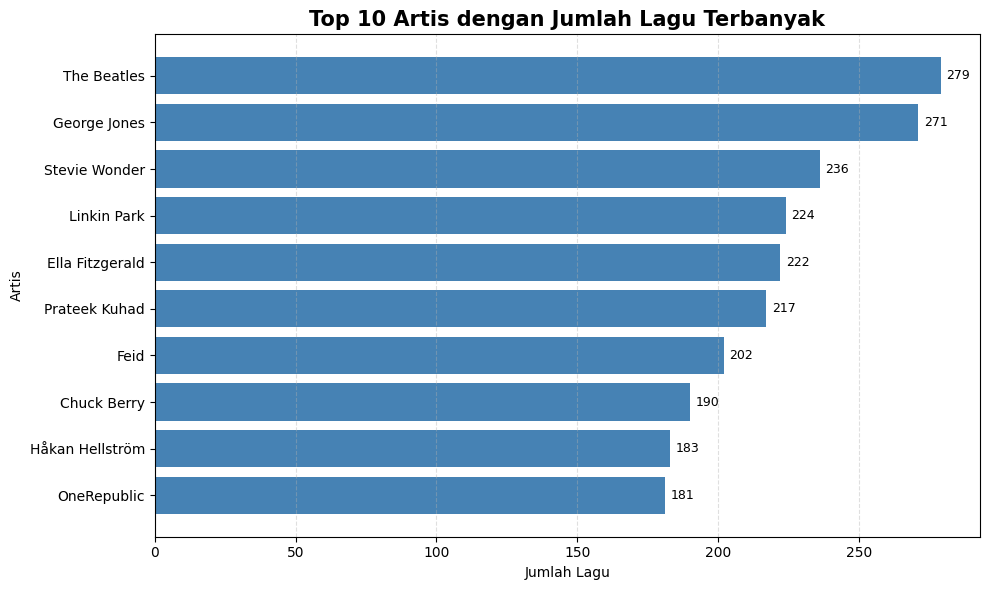

In [ ]:
import matplotlib.pyplot as plt

artist_pd = artist_count.limit(10).toPandas()

plt.figure(figsize=(10,6))

bars = plt.barh(
    artist_pd["artists"],
    artist_pd["Jumlah_Lagu"],
    color="steelblue"
)

plt.title("Top 10 Artis dengan Jumlah Lagu Terbanyak",
          fontsize=15,
          fontweight="bold")

plt.xlabel("Jumlah Lagu")
plt.ylabel("Artis")

plt.grid(axis="x", linestyle="--", alpha=0.4)

plt.gca().invert_yaxis()

for bar in bars:
    plt.text(
        bar.get_width()+2,
        bar.get_y()+bar.get_height()/2,
        f"{bar.get_width():.0f}",
        va="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [ ]:
popular_song = df.filter(df.popularity >= 80)

popular_song.select(
    "danceability",
    "energy",
    "acousticness",
    "valence"
).describe().show()

+-------+------------------+------------------+-------------------+-------------------+
|summary|      danceability|            energy|       acousticness|            valence|
+-------+------------------+------------------+-------------------+-------------------+
|  count|              1201|              1201|               1201|               1201|
|   mean|0.6481452955870108|0.6820728726061617|  0.188426279317236| 0.5137997502081603|
| stddev|0.1518214738212836|0.1709613467731559|0.23547906125814044|0.22871176184943104|
|    min|               0.0|           0.00342|            7.53E-6|                0.0|
|    max|             0.951|             0.989|              0.981|              0.979|
+-------+------------------+------------------+-------------------+-------------------+



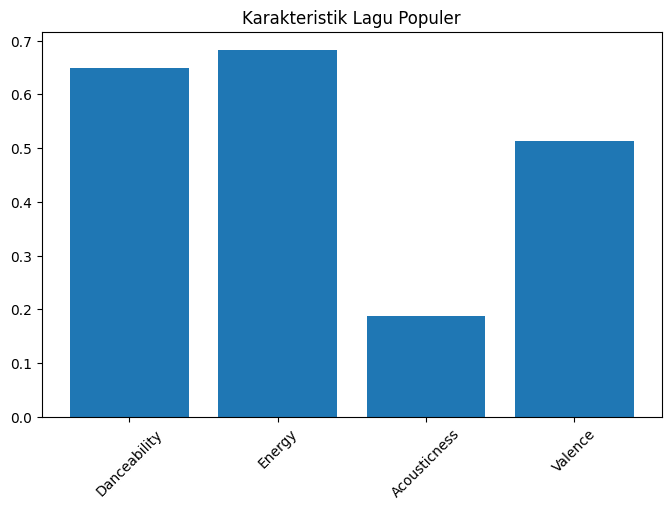

In [ ]:
from pyspark.sql.functions import avg

feature_avg = popular_song.select(
    avg("danceability").alias("Danceability"),
    avg("energy").alias("Energy"),
    avg("acousticness").alias("Acousticness"),
    avg("valence").alias("Valence")
)

feature_pd = feature_avg.toPandas().T

feature_pd.columns = ["Average"]

plt.figure(figsize=(8,5))

plt.bar(
    feature_pd.index,
    feature_pd["Average"]
)

plt.xticks(rotation=45)

plt.title("Karakteristik Lagu Populer")

plt.show()

In [ ]:
from pyspark.sql.functions import avg, round

genre_energy = (
    df.groupBy("track_genre")
      .agg(round(avg("energy"),3).alias("Average_Energy"))
      .orderBy("Average_Energy", ascending=False)
)

genre_energy.show(10)

+-------------+--------------+
|  track_genre|Average_Energy|
+-------------+--------------+
|  death-metal|         0.931|
|    grindcore|         0.924|
|    metalcore|         0.914|
|        happy|         0.911|
|    hardstyle|         0.901|
|drum-and-bass|         0.877|
|  black-metal|         0.875|
|  heavy-metal|         0.874|
|        party|         0.871|
|       j-idol|         0.869|
+-------------+--------------+
only showing top 10 rows


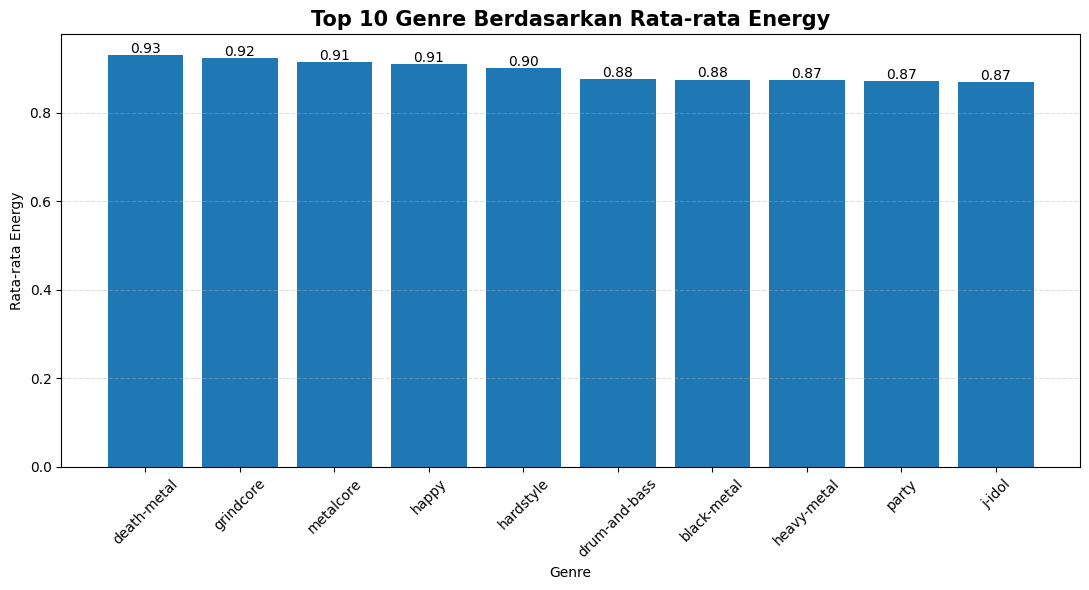

In [ ]:
import matplotlib.pyplot as plt

energy_pd = genre_energy.limit(10).toPandas()

plt.figure(figsize=(11,6))

bars = plt.bar(
    energy_pd["track_genre"],
    energy_pd["Average_Energy"]
)

plt.title("Top 10 Genre Berdasarkan Rata-rata Energy",
          fontsize=15,
          fontweight="bold")

plt.xlabel("Genre")
plt.ylabel("Rata-rata Energy")

plt.xticks(rotation=45)

plt.grid(axis="y", linestyle="--", alpha=0.4)

for bar in bars:
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height()+0.005,
        f"{bar.get_height():.2f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

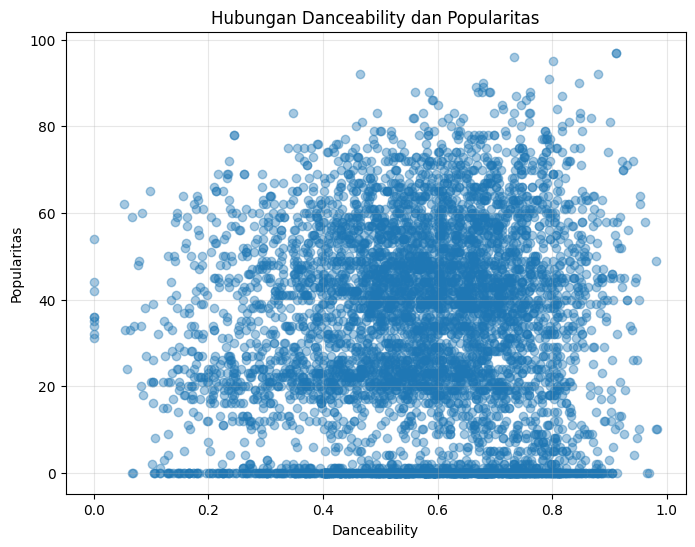

In [ ]:
sample_pd = df.select(
    "danceability",
    "popularity"
).sample(False,0.05,42).toPandas()

plt.figure(figsize=(8,6))

plt.scatter(
    sample_pd["danceability"],
    sample_pd["popularity"],
    alpha=0.4
)

plt.title("Hubungan Danceability dan Popularitas")

plt.xlabel("Danceability")

plt.ylabel("Popularitas")

plt.grid(alpha=0.3)

plt.show()

In [ ]:
feature_cols = [
    "popularity",
    "danceability",
    "energy",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo"
]

ml_df = df.select(feature_cols)
ml_df.show(5)

+----------+------------+------+------------+----------------+--------+-------+-------+
|popularity|danceability|energy|acousticness|instrumentalness|liveness|valence|  tempo|
+----------+------------+------+------------+----------------+--------+-------+-------+
|        60|       0.494| 0.652|      0.0754|         0.00256|   0.125|  0.298|137.018|
|        51|       0.592|  0.49|       0.395|             0.0|   0.333|  0.437| 99.994|
|        33|       0.564| 0.604|      0.0287|         4.74E-6|   0.108|  0.341|113.091|
|        28|       0.276| 0.289|       0.968|         0.00321|   0.137|  0.118| 86.465|
|        26|       0.382|   0.9|       0.018|             0.0|  0.0911|  0.644| 79.965|
+----------+------------+------+------------+----------------+--------+-------+-------+
only showing top 5 rows


In [ ]:
from pyspark.ml.feature import VectorAssembler

assembler = VectorAssembler(
    inputCols=feature_cols,
    outputCol="features"
)

assembled_df = assembler.transform(ml_df)

assembled_df.select("features").show(5, truncate=False)

+-----------------------------------------------------+
|features                                             |
+-----------------------------------------------------+
|[60.0,0.494,0.652,0.0754,0.00256,0.125,0.298,137.018]|
|[51.0,0.592,0.49,0.395,0.0,0.333,0.437,99.994]       |
|[33.0,0.564,0.604,0.0287,4.74E-6,0.108,0.341,113.091]|
|[28.0,0.276,0.289,0.968,0.00321,0.137,0.118,86.465]  |
|[26.0,0.382,0.9,0.018,0.0,0.0911,0.644,79.965]       |
+-----------------------------------------------------+
only showing top 5 rows


In [ ]:
from pyspark.ml.feature import StandardScaler

scaler = StandardScaler(
    inputCol="features",
    outputCol="scaledFeatures",
    withMean=True,
    withStd=True
)

scaler_model = scaler.fit(assembled_df)

scaled_df = scaler_model.transform(assembled_df)

scaled_df.select("scaledFeatures").show(5, truncate=False)

+---------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|scaledFeatures                                                                                                                                                       |
+---------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|[1.199792456244097,-0.41949495202457915,0.04221079358365873,-0.7202818358537512,-0.49583971959016726,-0.46514290554766213,-0.6791155910446782,0.49603259162556157]   |
|[0.7962969024098312,0.1452092807613363,-0.6018499536342921,0.24085554749975446,-0.5041096595163292,0.627422038351042,-0.14297646683595894,-0.7389983243000693]       |
|[-0.010694205258700457,-0.01613478574892544,-0.14862202040684536,-0.8607233746604117,-0.5040943472056847,-0.5544390788470754,-0.5132596029801102,-0.30211414360

In [ ]:
from pyspark.ml.clustering import KMeans

cost = []

for k in range(2,9):

    model = KMeans(
        featuresCol="scaledFeatures",
        k=k,
        seed=42
    ).fit(scaled_df)

    cost.append(model.summary.trainingCost)

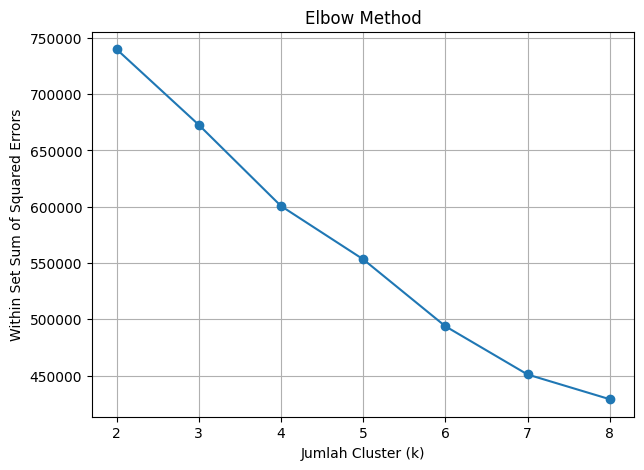

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))

plt.plot(range(2,9), cost, marker='o')

plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Within Set Sum of Squared Errors")

plt.title("Elbow Method")

plt.grid(True)

plt.show()

In [ ]:
kmeans = KMeans(
    featuresCol="scaledFeatures",
    predictionCol="cluster",
    k=4,
    seed=42
)

model = kmeans.fit(scaled_df)

cluster_df = model.transform(scaled_df)

cluster_df.select("cluster").show(10)

+-------+
|cluster|
+-------+
|      3|
|      3|
|      3|
|      2|
|      0|
|      1|
|      3|
|      3|
|      0|
|      0|
+-------+
only showing top 10 rows


In [ ]:
from pyspark.sql.functions import count

cluster_df.groupBy("cluster") \
          .agg(count("*").alias("Jumlah Lagu")) \
          .orderBy("cluster") \
          .show()

+-------+-----------+
|cluster|Jumlah Lagu|
+-------+-----------+
|      0|      28532|
|      1|      29178|
|      2|      23666|
|      3|      32624|
+-------+-----------+



In [ ]:
from pyspark.ml.evaluation import ClusteringEvaluator

evaluator = ClusteringEvaluator(
    featuresCol="scaledFeatures",
    predictionCol="cluster",
    metricName="silhouette"
)

score = evaluator.evaluate(cluster_df)

print("Silhouette Score :", score)

Silhouette Score : 0.2257279880151996


In [ ]:
from pyspark.sql.functions import avg

cluster_result = cluster_df.select(
    "cluster",
    *feature_cols
)

cluster_result.groupBy("cluster").agg(
    avg("popularity").alias("Avg Popularity"),
    avg("danceability").alias("Avg Danceability"),
    avg("energy").alias("Avg Energy"),
    avg("acousticness").alias("Avg Acousticness"),
    avg("valence").alias("Avg Valence"),
    avg("tempo").alias("Avg Tempo")
).show(truncate=False)

+-------+------------------+------------------+------------------+-------------------+-------------------+------------------+
|cluster|Avg Popularity    |Avg Danceability  |Avg Energy        |Avg Acousticness   |Avg Valence        |Avg Tempo         |
+-------+------------------+------------------+------------------+-------------------+-------------------+------------------+
|1      |32.681506614572626|0.4519443519089717|0.8281777023785019|0.09270442669545609|0.32476017770237875|138.1342055315647 |
|3      |54.317772192251105|0.6538981118195233|0.6587616325404606|0.2720944195518643 |0.5562692618930853 |116.72771833619451|
|2      |29.10948195723823 |0.4487100566213138|0.2825837892842059|0.7870120170075185 |0.2941188483900964 |109.10768642778599|
|0      |13.130660311229496|0.6826170965933027|0.7280947006869476|0.19951572349081775|0.6820265246039523 |122.81319262582439|
+-------+------------------+------------------+------------------+-------------------+-------------------+------------

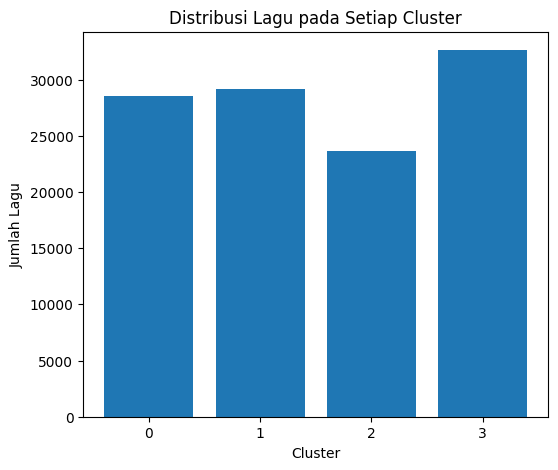

In [ ]:
cluster_pd = (
    cluster_df.groupBy("cluster")
              .count()
              .orderBy("cluster")
              .toPandas()
)

plt.figure(figsize=(6,5))

plt.bar(cluster_pd["cluster"].astype(str),
        cluster_pd["count"])

plt.xlabel("Cluster")

plt.ylabel("Jumlah Lagu")

plt.title("Distribusi Lagu pada Setiap Cluster")

plt.show()